# Dynamic — lag analysis for selected windows

Per-window dynamics (lags 1–30 days) on **existing** exports (2013–2022 train period). No re-export.

| Item | Value |
|------|-------|
| **Current** | `DATA_MODE = "fixwin"` → `data/sample_13_22_smallfixwin_uv_dt360_*` (128×128 @ 330,70, −45°) |
| **Old catalog** | `# DATA_MODE = "catalog"` — pool12, 12 Magic windows; `SELECT_WINDOWS = [7, 8]` |
| **Code** | [`window_dynamics.py`](window_dynamics.py) |
| **Outputs** | `Dynamic/data/fixwin_{export_key}/` or `Dynamic/data/window_{W:02d}_{export_key}/` |

Metrics (same as Mesh `analyze_mesh_export_dynamics.py`):
1. Lag autocorrelation (domain-mean anomaly)
2. Persistence RMSE
3. Spatial pattern correlation
4. Integral timescale
5. EKE decorrelation
6. Spectral-energy decorrelation

In [1]:
import json
import os
import sys
from pathlib import Path

NOTEBOOK_DIR = Path.cwd().resolve()
DYNAMIC_DIR = NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Dynamic" else NOTEBOOK_DIR / "Dynamic"
ROOT = DYNAMIC_DIR.parent
os.chdir(ROOT)
for _p in (ROOT, DYNAMIC_DIR):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import importlib
import window_dynamics as wd
importlib.reload(wd)

# --- user knobs (fix window) ---
DATA_MODE = "fixwin"
FIXWIN_KEY = "smallfixwin"
MAX_LAG_DAYS = 30
OUT_ROOT = DYNAMIC_DIR / "data"

DATA_PREFIX = ROOT / "data" / "sample_13_22_smallfixwin_uv_dt360"

# Old catalog (pool12, 12 Magic windows):
# DATA_MODE = "catalog"
# SELECT_WINDOWS = [7, 8]          # or list(range(1, 13))
# DATA_PREFIX = ROOT / "Shalow" / "data" / "select_window_12" / "sample_13_22_uv_dt360"

print(f"DATA_MODE: {DATA_MODE}")
print(f"DATA_PREFIX: {DATA_PREFIX}")
print(f"OUT_ROOT: {OUT_ROOT}")

if DATA_MODE == "catalog":
    catalog = wd.load_window_catalog(DATA_PREFIX)
    print("\nCatalog windows:")
    for entry in catalog["windows"]:
        w = int(entry["slot"]) + 1
        mark = " <-- selected" if w in SELECT_WINDOWS else ""
        print(f"  W{w:02d} slot={entry['slot']} {entry['export_key']}{mark}")
    print(f"\nSELECT_WINDOWS: {SELECT_WINDOWS}")
elif DATA_MODE == "fixwin":
    cfg = wd.load_export_config(DATA_PREFIX)
    print(f"\nFix window: {FIXWIN_KEY}")
    print(
        f"  {cfg['crop_height']}×{cfg['crop_width']} @ "
        f"({cfg['window_top']},{cfg['window_left']}) angle={cfg['window_angle']}°"
    )
    print(f"  period: {cfg['start_time']} → {cfg['end_time']}")
else:
    raise ValueError(f"DATA_MODE must be 'catalog' or 'fixwin', got {DATA_MODE!r}")

DATA_MODE: fixwin
DATA_PREFIX: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/data/sample_13_22_smallfixwin_uv_dt360
OUT_ROOT: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Dynamic/data

Fix window: smallfixwin
  128×128 @ (330,70) angle=-45.0°
  period: 2013-01-01 → 2022-12-31


In [2]:
# Export check (no re-export needed if arrays exist)
suffixes = ("_sims.npy", "_mask.npy", "_indices.npy", "_window.npy", "_export_config.json")
# Old catalog:
# suffixes = ("_sims_pool_k1.npy", "_mask_pool_k1.npy", "_indices.npy", "_window_catalog.json")

for suffix in suffixes:
    p = DATA_PREFIX.parent / f"{DATA_PREFIX.name}{suffix}"
    print(f"{'OK' if p.is_file() else 'MISSING':7} {p.name}")

OK      sample_13_22_smallfixwin_uv_dt360_sims.npy
OK      sample_13_22_smallfixwin_uv_dt360_mask.npy
OK      sample_13_22_smallfixwin_uv_dt360_indices.npy
OK      sample_13_22_smallfixwin_uv_dt360_window.npy
OK      sample_13_22_smallfixwin_uv_dt360_export_config.json


In [3]:
if DATA_MODE == "fixwin":
    summaries = [
        wd.analyze_fix_window(
            data_prefix=DATA_PREFIX,
            export_key=FIXWIN_KEY,
            out_root=OUT_ROOT,
            max_lag_days=MAX_LAG_DAYS,
        )
    ]
elif DATA_MODE == "catalog":
    summaries = wd.analyze_selected_windows(
        SELECT_WINDOWS,
        data_prefix=DATA_PREFIX,
        out_root=OUT_ROOT,
        max_lag_days=MAX_LAG_DAYS,
    )
else:
    raise ValueError(f"Unknown DATA_MODE: {DATA_MODE!r}")

# Old catalog-only:
# summaries = wd.analyze_selected_windows(
#     SELECT_WINDOWS,
#     data_prefix=DATA_PREFIX,
#     out_root=OUT_ROOT,
#     max_lag_days=MAX_LAG_DAYS,
# )

print(f"Finished {len(summaries)} window(s)")
for s in summaries:
    it = s["integral_timescales_days"]
    snap = s.get("lag_30d_snapshot", {})
    label = (
        f"fixwin {s['export_key']}"
        if s.get("data_mode") == "fixwin"
        else f"W{s['window']:02d} {s['export_key']}"
    )
    print(
        f"  {label:32s} | "
        f"T_int u={it['u_integral_timescale_days']:.1f}d v={it['v_integral_timescale_days']:.1f}d | "
        f"30d u_pat={snap.get('u_spatial_pattern_corr', float('nan')):.3f}"
    )

2026-07-05 17:26:39,086 | INFO | Window dynamics analysis smallfixwin
2026-07-05 17:26:39,088 | INFO | Data prefix: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/data/sample_13_22_smallfixwin_uv_dt360
2026-07-05 17:26:39,089 | INFO | Output -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Dynamic/data/fixwin_smallfixwin
2026-07-05 17:26:39,089 | INFO | Time series u=(3600, 128, 128) valid_pixels=16384 n_times=3600 dt_days=1.0
2026-07-05 17:26:46,534 | INFO | lag= 1d | u_ac=0.646 v_ac=0.257 | u_rmse=0.1347 v_rmse=0.1388 | u_pat=0.850 spec=0.985
2026-07-05 17:26:51,391 | INFO | lag= 2d | u_ac=0.670 v_ac=0.389 | u_rmse=0.1440 v_rmse=0.1551 | u_pat=0.825 spec=0.984
2026-07-05 17:26:56,249 | INFO | lag= 3d | u_ac=0.723 v_ac=0.489 | u_rmse=0.1544 v_rmse=0.1762 | u_pat=0.786 spec=0.981
2026-07-05 17:27:01,093 | INFO | lag= 4d | u_ac=0.599 v_ac=0.253 | u_rmse=0.1826 v_rmse=0.2108 | u_pat=0.704 spec=0.976
2026-07-05 17:27:05,937 | INFO | lag= 5d | u_ac=0.661 v_ac=0.421 | u_rmse=0.1901 v_rmse=


=== fixwin smallfixwin ===


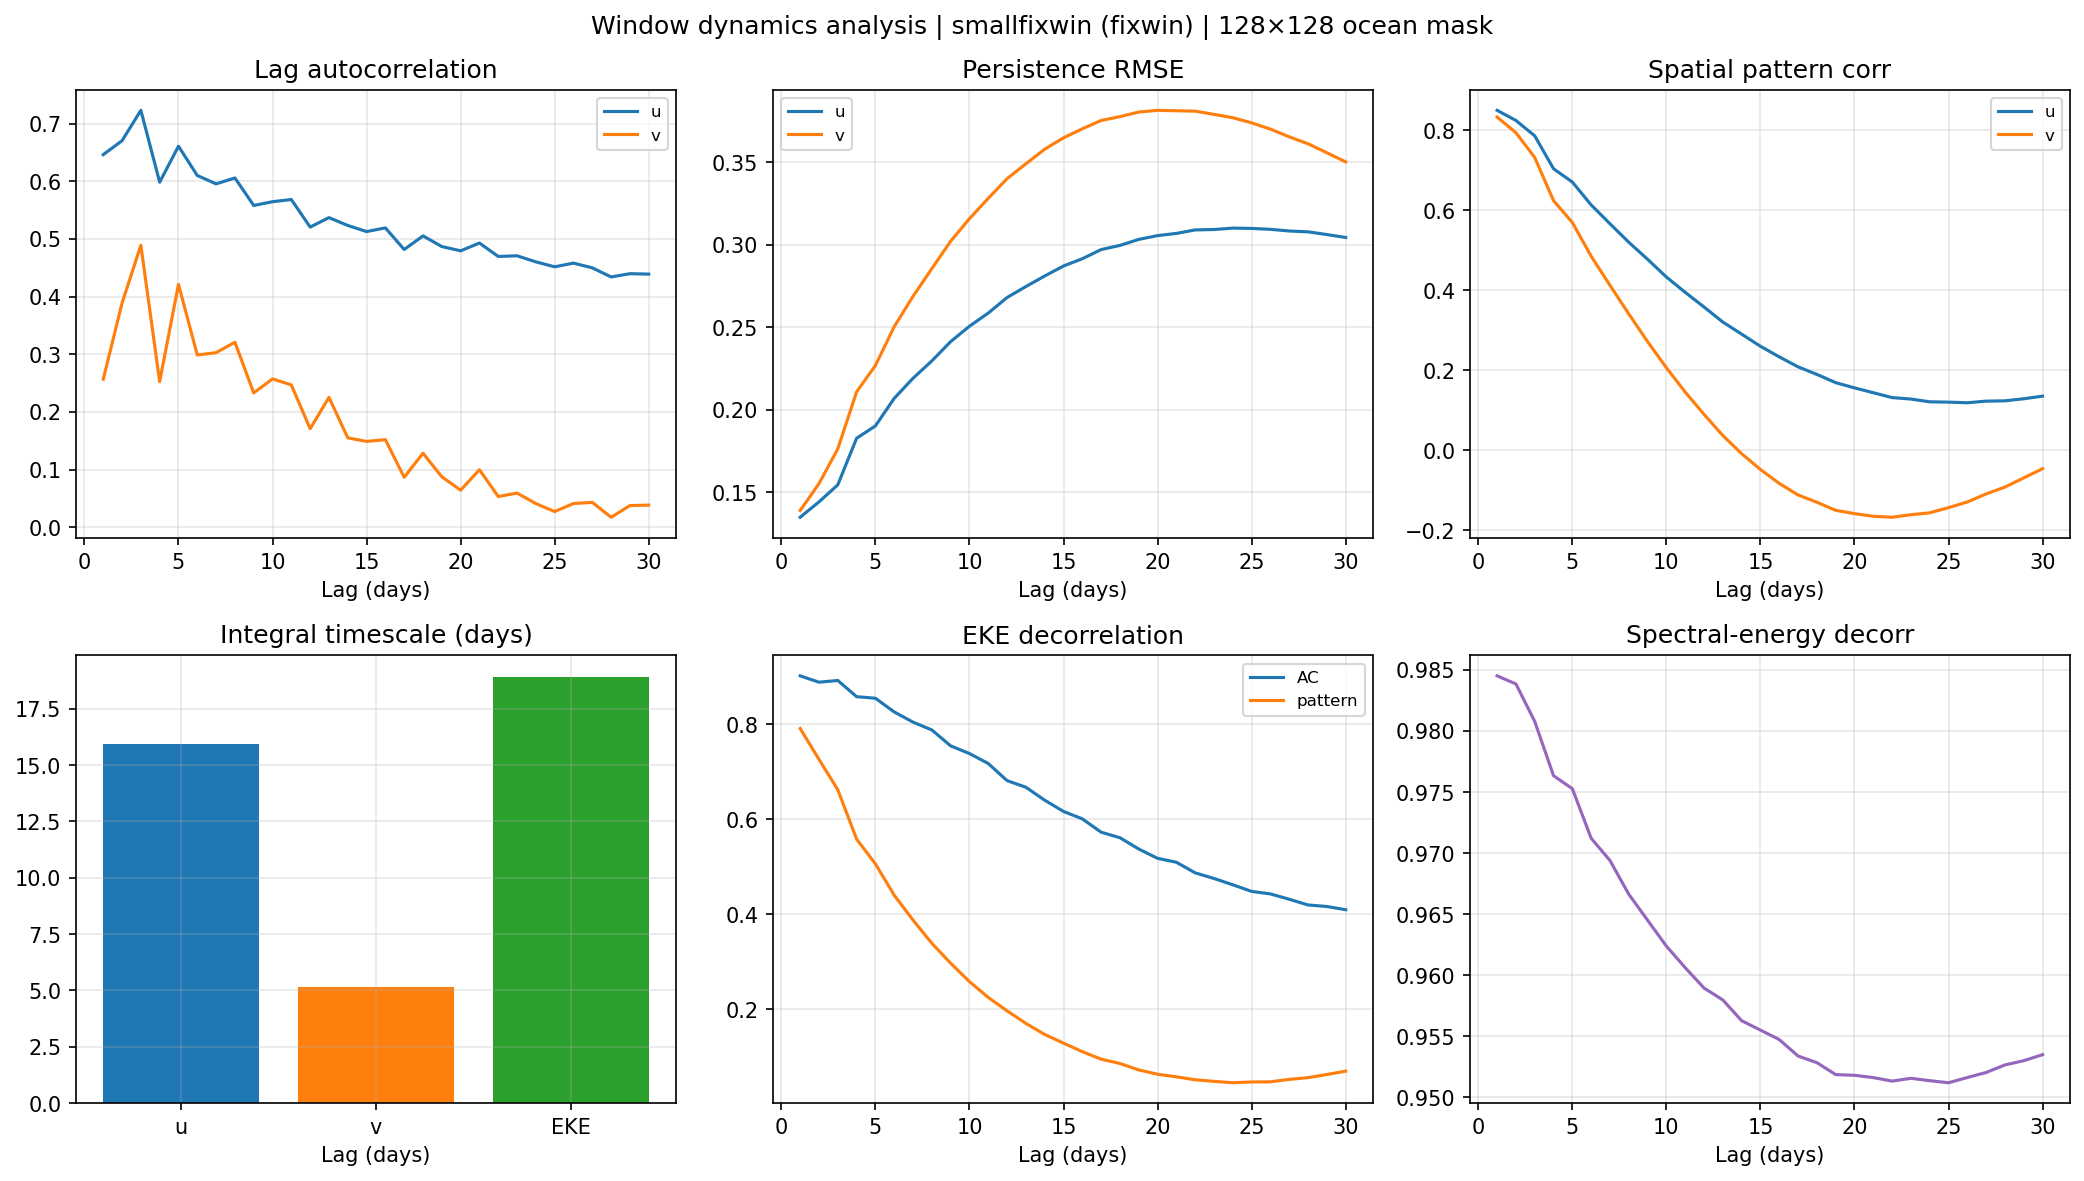

In [4]:
from IPython.display import Image, display

for s in summaries:
    out_dir = wd.result_out_dir(OUT_ROOT, s)
    dash = out_dir / "plots" / "00_dashboard.png"
    label = (
        f"fixwin {s['export_key']}"
        if s.get("data_mode") == "fixwin"
        else f"W{s['window']:02d} {s['export_key']}"
    )
    print(f"\n=== {label} ===")
    display(Image(filename=str(dash)))